# 12 · Agentic RAG: let the model decide when to search

Every system so far retrieves on **every** question, exactly once, with the question as the query.
That's wasteful for "What's 15% of 200?", and too little for "What's the signature dish at the
restaurant of the cheapest hotel?", which needs two lookups, the second depending on the first.

An **agent** gives the model tools and lets it decide: answer directly, search, look something up
in a table, or search again with a better query.

**In this notebook you will:**
- give the model three tools and run the classic **tool loop** with the plain OpenAI SDK,
- build the same behaviour as an explicit **LangGraph** state machine, with query rewriting and a self-check,
- compare both against the fixed pipeline on accuracy, latency and cost.

Cost: about $0.01.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: the agent module (it builds or reuses the baseline index on first use)
import importlib.util
import json

import pandas as pd

from raglab import agent
from raglab import evaluation as ev
from raglab.display import show_diagram

settings = get_settings()
pd.set_option("display.max_colwidth", 100)

In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

## 1. What an agent adds: decisions

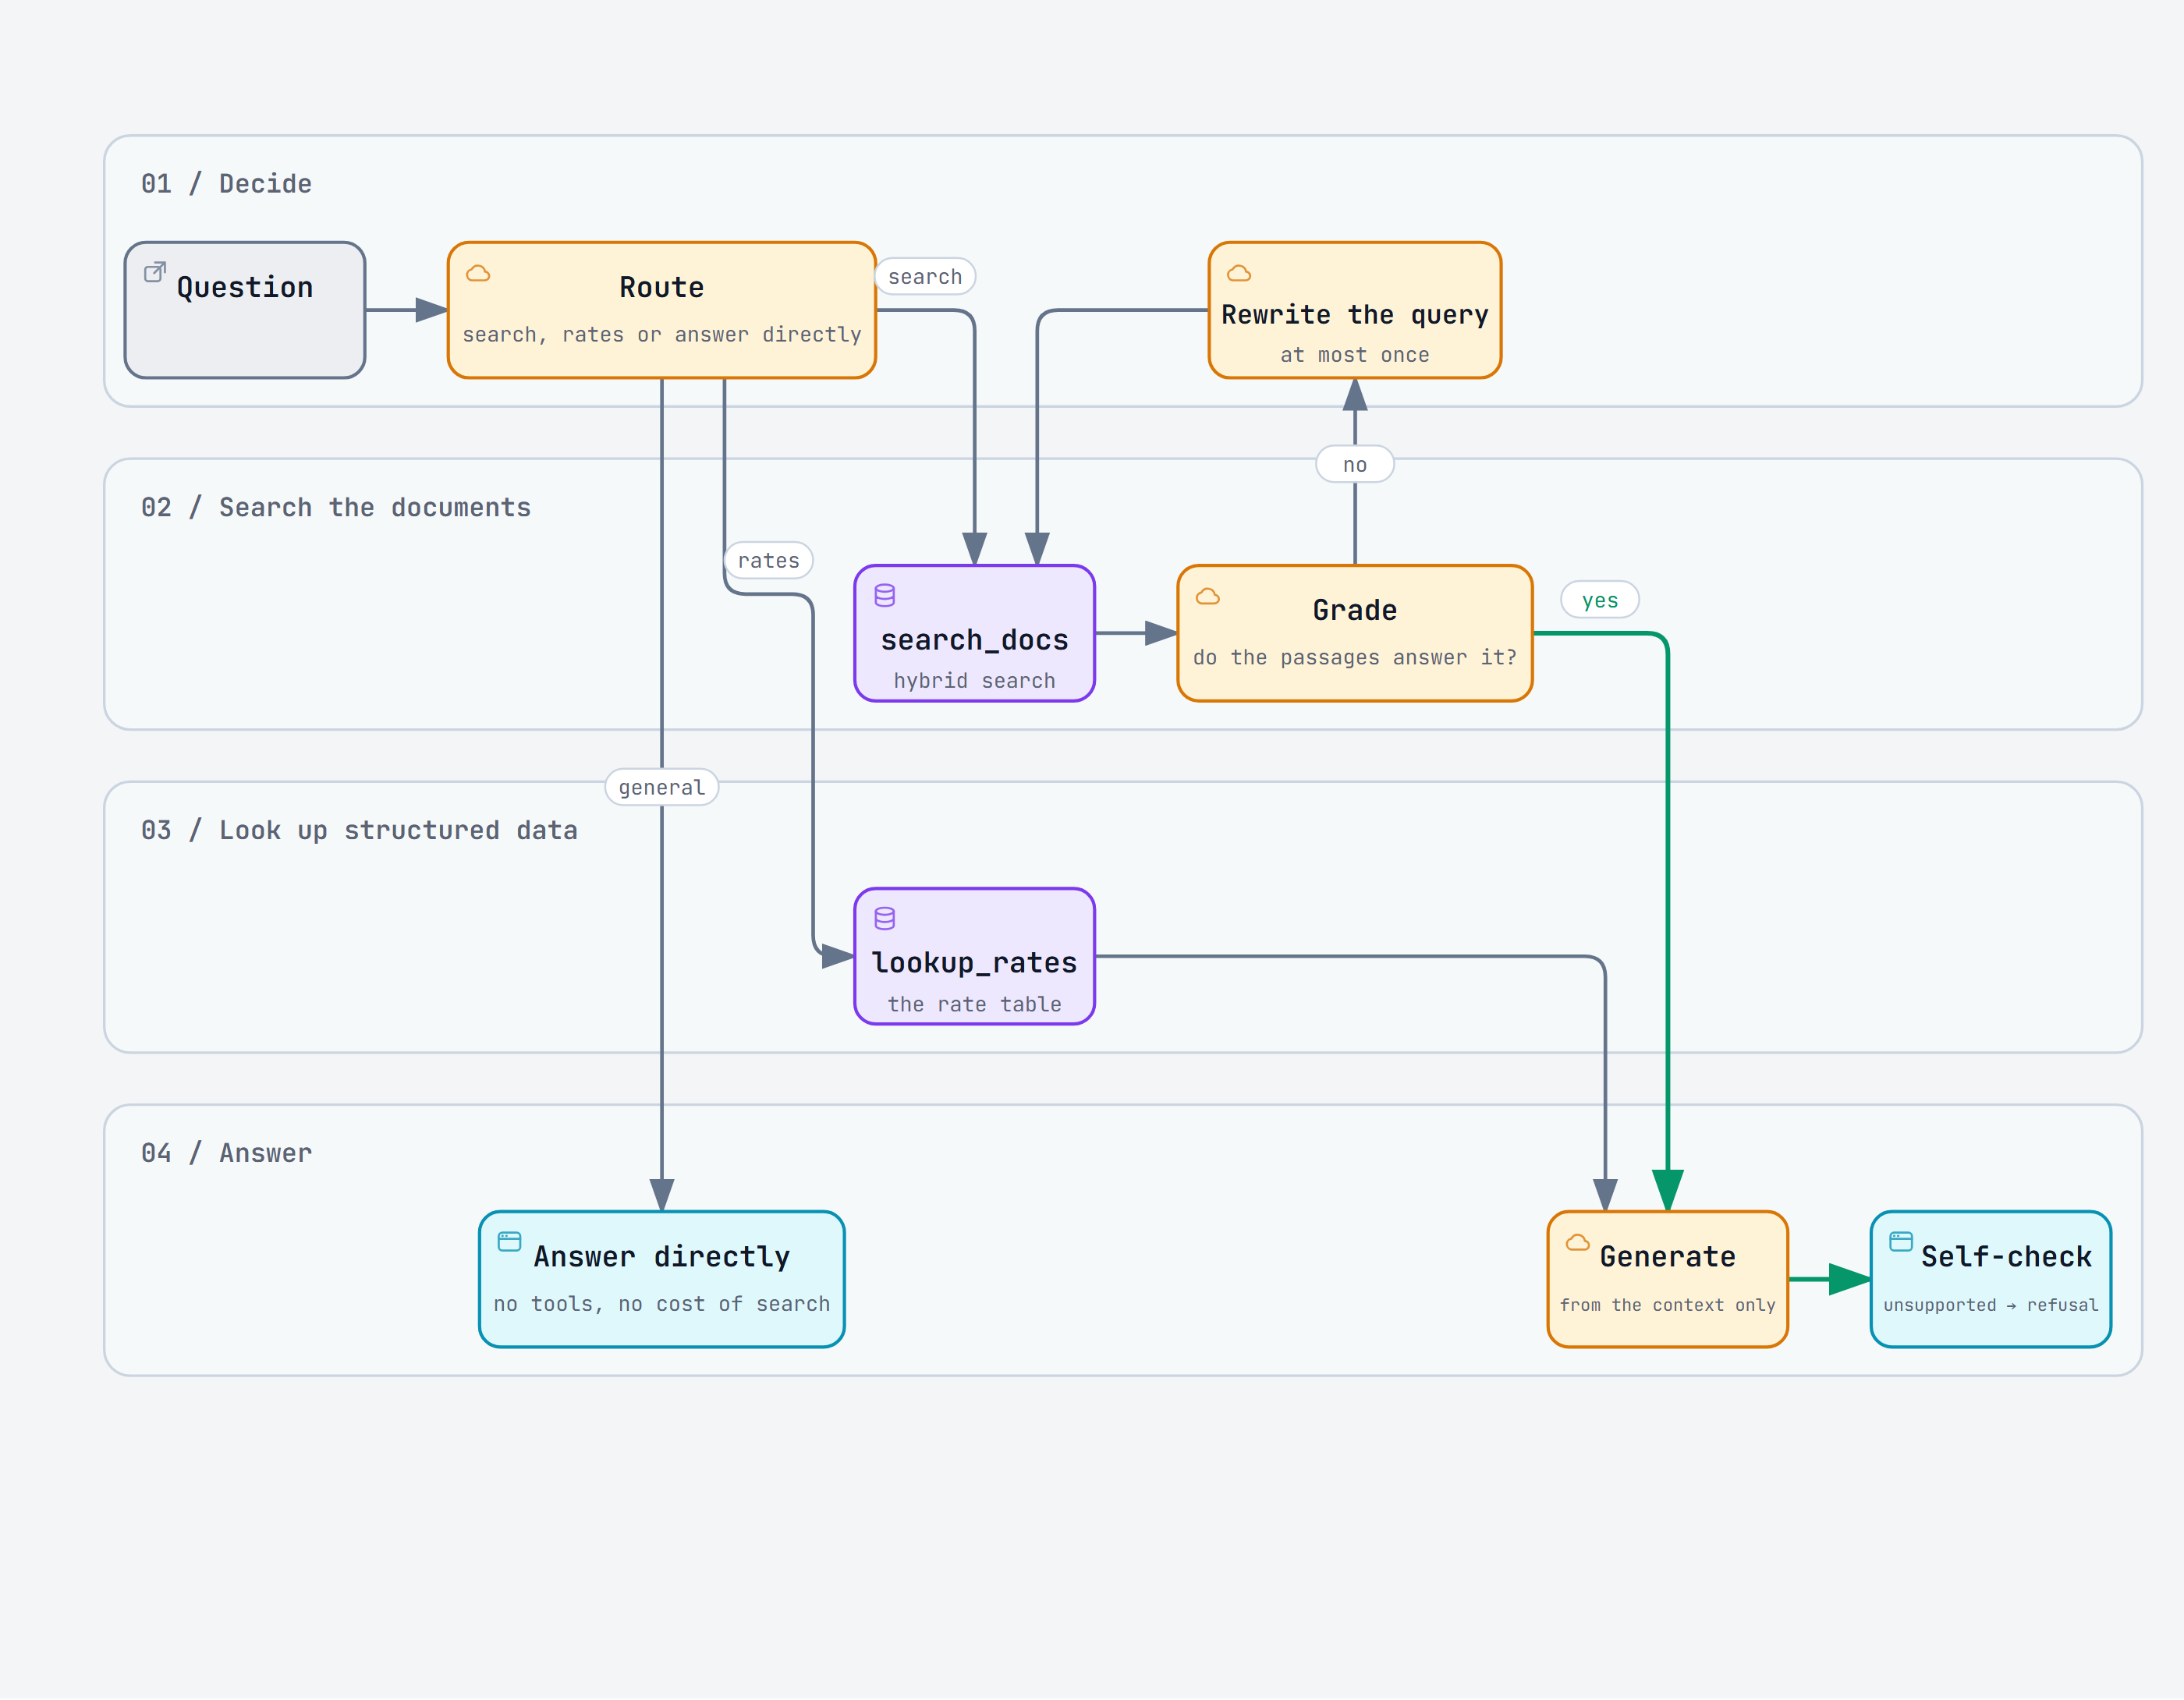

[Open interactive version](../diagrams/agent_loop.html)

In [4]:
show_diagram("agent_loop")

## 2. The tools

A tool is a plain Python function plus a JSON description the model reads. We have three:

| Tool | Data | Good for |
|---|---|---|
| `search_docs(query, hotel=None)` | hybrid search over the documents (notebook 07) | policies, dining, FAQ, anything written in prose |
| `lookup_rates(hotel, room_type, season)` | the rate table, filtered with pandas | prices: exact numbers, no retrieval guesswork |
| `list_hotels()` | the hotel database (one row per hotel) | comparisons and filters: "earliest", "cheapest", "in Asia with a pool" |

The last two matter: notebooks 06 and 07 showed that questions comparing **all** hotels are the
hardest for retrieval, because no single chunk contains the answer. A table does.

In [5]:
print(agent.search_docs("pets allowed", hotel="Token Lisbon", k=1))
print(agent.lookup_rates("Token Cusco", season="low"))
pd.DataFrame(agent.list_hotels())

[nb04_baseline] reusing index (109 chunks)
[{'source_file': 'room_rates.csv', 'text': 'Token Lisbon — rates\n\nhotel: Token Lisbon\ncity: Lisbon\nroom_type: Suite\nseason: low\nnightly_rate_usd: 530\nmax_guests: 4'}]
[{'hotel': 'Token Cusco', 'city': 'Cusco', 'room_type': 'Standard', 'season': 'low', 'nightly_rate_usd': 95, 'max_guests': 2, 'continent': 'South America'}, {'hotel': 'Token Cusco', 'city': 'Cusco', 'room_type': 'Deluxe', 'season': 'low', 'nightly_rate_usd': 135, 'max_guests': 3, 'continent': 'South America'}, {'hotel': 'Token Cusco', 'city': 'Cusco', 'room_type': 'Suite', 'season': 'low', 'nightly_rate_usd': 210, 'max_guests': 4, 'continent': 'South America'}]


,hotel_name,city,country,continent,star_rating,price_per_night,has_pool,has_spa,rooms,check_in
0,Token Lisbon,Lisbon,Portugal,Europe,4,240,True,False,132,3:00 PM
1,Token Kyoto,Kyoto,Japan,Asia,5,520,False,True,64,4:00 PM
2,Token Vancouver,Vancouver,Canada,North America,4,310,True,True,210,3:30 PM
3,Token Queenstown,Queenstown,New Zealand,Oceania,4,280,False,True,88,2:00 PM
4,Token Marrakech,Marrakech,Morocco,Africa,5,410,True,True,54,1:00 PM
5,Token Singapore,Singapore,Singapore,Asia,5,690,True,True,340,2:30 PM
6,Token Reykjavík,Reykjavík,Iceland,Europe,3,190,False,False,76,4:30 PM
7,Token Cusco,Cusco,Peru,South America,3,95,False,False,40,12:00 PM


This is what the model sees for one tool, an OpenAI function-tool schema:

In [6]:
print(json.dumps(agent.TOOL_SPECS[1], indent=2))

{
  "type": "function",
  "function": {
    "name": "lookup_rates",
    "description": "Nightly room rates in USD. Room types: Standard, Deluxe, Suite. Seasons: low, high. Every argument is optional; leave hotel out to get all hotels. Rows include the continent.",
    "parameters": {
      "type": "object",
      "properties": {
        "hotel": {
          "type": "string"
        },
        "room_type": {
          "type": "string",
          "enum": [
            "Standard",
            "Deluxe",
            "Suite"
          ]
        },
        "season": {
          "type": "string",
          "enum": [
            "low",
            "high"
          ]
        }
      }
    }
  }
}


## 3. The tool loop

The whole agent is a loop (`agent.run_tool_loop`):

```python
messages = [system_prompt, question]
for each round (at most max_steps):
    reply = model(messages, tools=TOOL_SPECS)
    if reply has no tool calls: return reply.text        # the model decided it's done
    for each tool call: run the function, append its result as a "tool" message
```

The system prompt tells it when to use tools: Token-specific facts always come from tools, general
knowledge never needs them. Watch the decisions (`verbose=True` prints every tool call):

In [7]:
demo_questions = [
    "What is 15% of 200?",
    "What time is check-in at Token Cusco?",
    "What is the cheapest suite in Asia in low season?",
    "What is the signature dish at the restaurant of the cheapest Token hotel?",
]
for q in demo_questions:
    print(f"Q: {q}")
    result = agent.run_tool_loop(q, verbose=True)
    print(f"A: {result.answer}\n   searched={result.searched}, tool calls={len(result.steps)}, {result.latency_ms} ms\n")

Q: What is 15% of 200?


A: 15% of 200 is 30.
   searched=False, tool calls=0, 1438 ms

Q: What time is check-in at Token Cusco?


  -> search_docs({'query': 'check-in time', 'hotel': 'Token Cusco'})  =>  [{"source_file": "hotel_profiles.pdf", "text": "Token Cusco — profile\n\nToken Cusco\nToken Cusco oc


A: Check-in at Token Cusco starts at 12:00 PM.
   searched=True, tool calls=1, 1773 ms

Q: What is the cheapest suite in Asia in low season?


  -> list_hotels({})  =>  [{"hotel_name": "Token Lisbon", "city": "Lisbon", "country": "Portugal", "continent": "Europe", "sta


  -> lookup_rates({'room_type': 'Suite', 'season': 'low'})  =>  [{"hotel": "Token Lisbon", "city": "Lisbon", "room_type": "Suite", "season": "low", "nightly_rate_us


A: Token Kyoto has the cheapest suite in Asia in low season at **$1,145 per night**.
   searched=True, tool calls=2, 2477 ms

Q: What is the signature dish at the restaurant of the cheapest Token hotel?


  -> list_hotels({})  =>  [{"hotel_name": "Token Lisbon", "city": "Lisbon", "country": "Portugal", "continent": "Europe", "sta


  -> search_docs({'query': 'restaurant signature dish', 'hotel': 'Token Cusco'})  =>  [{"source_file": "dining_guide.md", "text": "Token Cusco — dining\n\n## Token Cusco  \n### Inti Kitc


A: The cheapest Token hotel is Token Cusco. Its restaurant, Inti Kitchen, serves **alpaca loin with red quinoa** as its signature dish.
   searched=True, tool calls=2, 2627 ms



Four questions, four strategies, all chosen by the model:

- the arithmetic needs **no** tool, so it costs one short call and no retrieval;
- the check-in time and the suite price come from tools. Which tool the model picks can change
  between runs (both `search_docs` and `list_hotels` know the check-in time), and for the price it
  typically uses the structured ones, `list_hotels` to find the Asian hotels and `lookup_rates`;
- the last question is **multi-hop**: the model first finds the cheapest hotel, then looks up its
  restaurant. A fixed pipeline can't do that: it searches once, with the original question.

## 4. The same idea as a graph (LangGraph)

The tool loop is flexible, but its behaviour lives inside the model's head: hard to test, hard to
bound. **LangGraph** makes the control flow explicit. Each node is a function, edges decide what
runs next, and you can add steps the model would skip on its own:

- `route`: one cheap call decides *search*, *rates* or *answer directly*,
- `grade`: do the retrieved passages actually answer the question? If not, `rewrite` the query
  and search once more,
- `self_check`: is every fact in the answer supported by the context? If not, refuse.

LangGraph needs the optional `[agent]` extra.

In [8]:
HAS_LANGGRAPH = importlib.util.find_spec("langgraph") is not None
if HAS_LANGGRAPH:
    graph = agent.build_graph()
    print(graph.get_graph().draw_mermaid())  # the graph as Mermaid text (paste it into any Mermaid viewer)
else:
    print("Skipping the LangGraph half: install it with `uv sync --extra agent` and restart the kernel.")

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	route(route)
	answer_directly(answer_directly)
	rates(rates)
	retrieve(retrieve)
	grade(grade)
	rewrite(rewrite)
	generate(generate)
	self_check(self_check)
	__end__([<p>__end__</p>]):::last
	__start__ --> route;
	generate --> self_check;
	grade -.-> generate;
	grade -.-> rewrite;
	rates --> generate;
	retrieve --> grade;
	rewrite --> retrieve;
	route -.-> answer_directly;
	route -.-> rates;
	route -.-> retrieve;
	answer_directly --> __end__;
	self_check --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [9]:
if HAS_LANGGRAPH:
    for q in demo_questions + ["Who is the general manager of Token Lisbon?"]:
        result = agent.run_graph(q)
        print(f"Q: {q}\nA: {result.answer}")
        print("   path:", " -> ".join(s.name for s in result.steps), f"({result.latency_ms} ms)\n")

Q: What is 15% of 200?
A: 15% of 200 is 30.
   path: route -> answer_directly (1351 ms)



Q: What time is check-in at Token Cusco?
A: Check-in at Token Cusco starts at 12:00 PM.
   path: route -> search_docs -> grade -> generate -> self_check (4448 ms)



Q: What is the cheapest suite in Asia in low season?
A: The cheapest low-season suite in Asia is Token Kyoto at $1,145 per night.
   path: route -> lookup_rates -> generate -> self_check (2002 ms)



Q: What is the signature dish at the restaurant of the cheapest Token hotel?
A: I couldn't find that in the Token Hotels documents.
   path: route -> search_docs -> grade -> rewrite -> search_docs -> grade -> generate -> self_check (4445 ms)



Q: Who is the general manager of Token Lisbon?
A: I couldn't find that in the Token Hotels documents.
   path: route -> search_docs -> grade -> rewrite -> search_docs -> grade -> generate -> self_check (4770 ms)



Read the paths. The graph routes the arithmetic straight to an answer and the price question to
the rate table, and it refuses the unanswerable question after one rewrite. But the multi-hop
question shows the price of a fixed graph: it only has `search_docs` and `lookup_rates`, so
"the cheapest hotel" has to be found by searching, and the rewrite may or may not get there.
The tool loop simply called `list_hotels` first. **Explicit control flow is easier to test and
bound; a free tool loop is more flexible.** Real systems often combine them: a graph whose nodes
are small tool loops.

## 5. Is it worth it? Measure.

The default run compares the three systems on the 5 quick questions plus the 5 questions that need
no search at all. The full run (`RAGLAB_FULL_RUN=1`) covers all 40 questions.

In [10]:
items = ev.load_eval("quick") + ev.load_eval("full", categories={"no_search_needed"})
if settings.full_run:
    items = ev.load_eval("full") + ev.load_eval("full", categories={"no_search_needed"})
systems = ("pipeline", "tool_loop", "graph") if HAS_LANGGRAPH else ("pipeline", "tool_loop")

compare = ev.run_or_load(
    "nb12_agent_compare",
    lambda: agent.compare_with_pipeline(items, systems=systems),
    meta={"systems": list(systems)},
)
summary = compare.groupby("system").agg(
    accuracy=("correct", "mean"),
    searched=("searched", "mean"),
    median_latency_ms=("latency_ms", "median"),
    cost_per_1000_questions=("cost_usd", lambda c: c.mean() * 1000),
)
summary.round(3)

[nb04_baseline] reusing index (109 chunks)


,accuracy,searched,median_latency_ms,cost_per_1000_questions
system,,,,
graph,0.9,0.5,2694.5,0.134
pipeline,0.5,1.0,689.0,0.053
tool_loop,1.0,0.5,1127.5,0.135


In [11]:
compare.pivot_table(index="category", columns="system", values="correct", aggfunc="mean").round(2)

system,graph,pipeline,tool_loop
category,,,
conflicting_versions,1.0,1.0,1.0
factual,1.0,1.0,1.0
metadata_filter,0.0,1.0,1.0
multi_hop,1.0,1.0,1.0
no_search_needed,1.0,0.0,1.0
unanswerable,1.0,1.0,1.0


## 6. What the numbers say

In the run saved here:

- **The pipeline fails every "no search needed" question**: its grounded prompt refuses anything
  that isn't in the documents, so "What is 15% of 200?" gets the refusal sentence. Both agents
  answer those directly, without searching (that's the 0.5 in `searched`: half the questions).
- **On the hotel questions** the default run has only **one question per category**, so a single
  miss swings a category between 1.0 and 0.0. Read those rows as anecdotes; the full run (all
  40 questions) is the fair test. Agents run several model calls per question, so their answers
  also vary more from run to run than the pipeline's.
- **The price is latency and cost**: each agent answer takes several model calls instead of one,
  so it is slower and costs two to three times as much per question as the pipeline (compare
  `median_latency_ms` and `cost_per_1000_questions`). The graph's grade and self-check calls
  make it the slowest.

**When is an agent worth it?** When questions vary: some need no search, some need several, some
need structured data. When every question is "look this up in the documents", a well-tuned
pipeline (notebooks 07 and 08) is faster, cheaper and easier to test. Measure on *your* questions
before you choose.

## Your turn

1. Add a `max_steps=2` limit to the multi-hop question. What does the tool loop do when it runs out of steps?
2. Give the graph a `list_hotels` route. Does the multi-hop question improve?
3. Ask the tool loop something with a trap, e.g. "What's the price of a suite at Token Paris?" Does it refuse?

## Key takeaways

- An agent's value is **decisions**: whether to search, which tool, and whether to search again.
- Give agents structured tools for structured questions; retrieval is weakest at "compare all X".
- A free tool loop is flexible; an explicit graph is testable and bounded. Both are a few dozen lines.
- Agents cost more calls per question. Measure accuracy, latency and cost against a plain pipeline.

**Added to raglab:** `agent.search_docs / lookup_rates / list_hotels / TOOL_SPECS / run_tool_loop /
build_graph / run_graph / compare_with_pipeline / ToolCall / AgentResult`.

# Series wrap-up

You started with RAG in 40 lines of plain Python (notebook 01) and ended with an evaluated,
defended, deployable service and an agent. The three things this series set out to give you:

1. **Judge and tune someone else's RAG system.** Build an eval set with unanswerable and
   conflicting questions (05), measure retrieval separately from generation (05, 08), triage every
   failure (08), and try cheap fixes before clever ones (06, 07).
2. **A working service you can adapt and deploy.** Incremental indexing and versions (09),
   verifiable answers and injection defence (10), and a FastAPI service with auth, rate limits,
   cost logging and a Cloud Run deploy guide (11).
3. **An agent that decides when to search.** Tools, a tool loop and a graph, measured against
   the pipeline (12).

The habit that ties them together: **measure, change one thing, measure again.**

In [12]:
cost.report()

model                       calls   in tokens  out tokens       USD
gpt-6-luna                    110      48,177       1,257    0.0054
text-embedding-3-small          8         118           0    0.0000
total                         118                            0.0054
